# 05 Clustering by time of day (K-means)
Groups LSOAs by their **bus service pattern across morning, off-peak and evening**.

Inputs: `lsoa_base.parquet`, `lsoa_frequency.parquet` (from notebook 04).
Features: the **share** of service in each band (morning / off-peak / evening: the time-of-day *shape*) plus a down-weighted log of total service (the *level*), standardised.
Using shares stops clusters being driven only by how much service an area has.
LSOAs with **no service** at all are kept as their own group, not clustered.
k is chosen with the elbow plot and silhouette score (k = 2 to 8). Run from `notebooks/`.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
CLEAN = Path("../data/clean")
base = pd.read_parquet(CLEAN / "lsoa_base.parquet")
freq = pd.read_parquet(CLEAN / "lsoa_frequency.parquet")
df = base.merge(freq, on="LSOA21CD", how="left").fillna({c: 0 for c in freq.columns if c.startswith("freq_")})
BANDS = ["freq_morning", "freq_off_peak", "freq_evening"]
df["any_service"] = df[BANDS].sum(axis=1) > 0
print(len(df), "LSOAs;", (~df.any_service).sum(), "with no service")

33755 LSOAs; 2348 with no service


## 1. Features

In [2]:
LEVEL_WEIGHT = 1.0      # 0 = shape only; try 0.5 / 1.5 and compare (sensitivity for the report)
# Only areas with some service are clustered; areas with none become their own group (-1) further down
svc = df.loc[df.any_service, BANDS]
total = svc.sum(axis=1)
# Shape of the day: each band's share of the area's departures (sums to 1), so a morning-heavy area looks different from an all-day one whatever its size
X = (svc.div(total, axis=0)).add_prefix("share_")
# Overall level of service on a log scale so a few very busy areas do not dominate (divided by 3 = average over the three bands)
X["log_level"] = np.log1p(total / 3)
# Put all features on the same scale so no single feature dominates the distance calculation
Xs = StandardScaler().fit_transform(X)
# Optionally turn the level feature up or down (1.0 = same weight as the shares)
Xs[:, -1] *= LEVEL_WEIGHT
X.describe().T

,count,mean,std,min,25%,50%,75%,max
share_freq_morning,31407.0,0.332810,0.058171,0.000000,0.317351,0.332842,0.345940,1.000000
share_freq_off_peak,31407.0,0.350070,0.073043,0.000000,0.328506,0.342193,0.362637,1.000000
share_freq_evening,31407.0,0.317120,0.063987,0.000000,0.306220,0.325954,0.338617,1.000000
log_level,31407.0,2.876093,1.028571,0.054067,2.203378,2.899588,3.556934,7.612666


## 2. Choose k (elbow and silhouette)

In [3]:
rng = np.random.default_rng(42)
idx = rng.choice(len(Xs), size=min(10_000, len(Xs)), replace=False)   # silhouette on a sample (speed)
# Try k = 2 to 8. Inertia gives the elbow plot; silhouette says how well separated the groups are (higher is better)
res = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    res.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Xs[idx], km.labels_[idx])})
res = pd.DataFrame(res); res.round(3)

,k,inertia,silhouette
0,2,96072.531,0.729
1,3,77846.523,0.285
2,4,62531.595,0.296
3,5,54830.347,0.297
4,6,48417.104,0.296
5,7,43631.091,0.274
6,8,39164.375,0.272


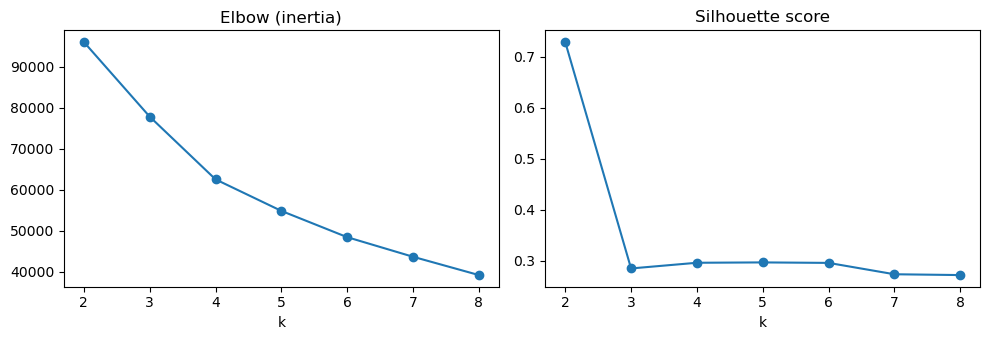

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(res.k, res.inertia, "o-"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(res.k, res.silhouette, "o-"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.tight_layout()

## 3. Fit the chosen k
Set `K` after looking at the plots (highest silhouette, with a visible elbow, and clusters you can explain).

In [5]:
K = 4   # chosen by hand: k=2 or 3 only separates "lots" from "little" service; k=4 also isolates
        # peak-only and off-peak-only areas. Justify in the report with the plots above.
print("best silhouette at k =", int(res.loc[res.silhouette.idxmax(), "k"]))
print("Using k =", K)
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xs)
df["cluster"] = -1                                  # -1 = no service
df.loc[df.any_service, "cluster"] = km.labels_

best silhouette at k = 2
Using k = 4


## 4. Cluster profiles
Mean departures per hour in each band. Use these to name the clusters (e.g. commuter-peak, all-day frequent, low-frequency).

In [6]:
# Average departures per hour in each band for each cluster; notebook 06 uses this to name the clusters
prof = df.groupby("cluster")[BANDS].mean().round(2)
prof["n_lsoas"] = df.groupby("cluster").size()
prof["mean_imd_score"] = df.groupby("cluster")["imd_score"].mean().round(1)
prof["mean_pop_density"] = df.groupby("cluster")["pop_density"].mean().round(0)
prof

,freq_morning,freq_off_peak,freq_evening,n_lsoas,mean_imd_score,mean_pop_density
cluster,,,,,,
-1,0.00,0.00,0.00,2348,20.2,12442.0
0,8.91,9.37,8.74,15023,19.2,4203.0
1,50.74,52.08,49.86,15278,24.6,5056.0
2,1.80,4.57,0.80,628,17.7,3804.0
3,3.93,2.16,1.23,478,16.0,2822.0


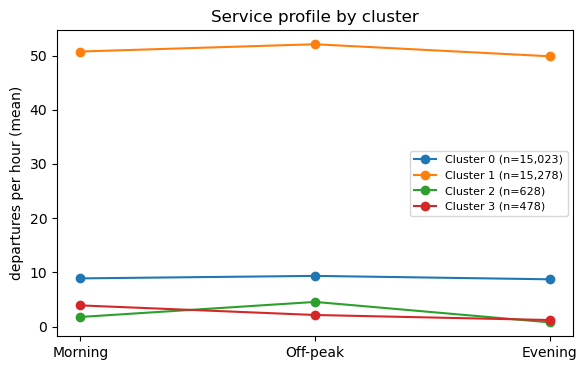

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.8))
for c, row in prof.drop(index=-1, errors="ignore").iterrows():
    ax.plot(["Morning", "Off-peak", "Evening"], row[BANDS].values, "o-", label=f"Cluster {c} (n={int(row.n_lsoas):,})")
ax.set_ylabel("departures per hour (mean)"); ax.legend(fontsize=8); ax.set_title("Service profile by cluster")
plt.tight_layout()

## 5. Save

In [8]:
df[["LSOA21CD", "cluster"] + BANDS].to_parquet(CLEAN / "lsoa_clusters.parquet", index=False)
res.to_csv(CLEAN / "kmeans_selection.csv", index=False)
prof.to_csv(CLEAN / "cluster_profiles.csv")
print("saved")

saved
